In [4]:
import pandas as pd

In [5]:
import numpy as np
import seaborn as sns

In [6]:
import matplotlib.pyplot as plt

%matplotlib inline

In [7]:
df=pd.read_csv(" https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")

In [8]:
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [9]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [10]:
df=df.astype({
    col:'object'
    for col in df.select_dtypes(include=['string']).columns})

In [11]:
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [12]:
strings=list(df.dtypes[df.dtypes=='object'].index)
strings

['origin', 'fuel_type', 'drivetrain']

In [13]:
df.head

<bound method NDFrame.head of       model_year  origin fuel_type         drivetrain  num_doors  \
0           2006  Europe  Gasoline  Front-wheel drive          4   
1           2008  Europe    Diesel  Front-wheel drive          4   
2           1996    Asia  Gasoline  Front-wheel drive          5   
3           1989  Europe  Gasoline  Front-wheel drive          4   
4           1994     USA    Diesel  Front-wheel drive          3   
...          ...     ...       ...                ...        ...   
9995        2005     USA  Gasoline    All-wheel drive          4   
9996        1993    Asia  Gasoline    All-wheel drive          2   
9997        2014     USA  Gasoline    All-wheel drive          3   
9998        2004     USA    Hybrid   Rear-wheel drive          5   
9999        2011     USA    Diesel  Front-wheel drive          4   

      engine_displacement  num_cylinders  horsepower  vehicle_weight  \
0                    2180              6       243.0            3870   
1        

In [14]:
df.shape

(10000, 11)

In [15]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [16]:
df.info

<bound method DataFrame.info of       model_year  origin fuel_type         drivetrain  num_doors  \
0           2006  Europe  Gasoline  Front-wheel drive          4   
1           2008  Europe    Diesel  Front-wheel drive          4   
2           1996    Asia  Gasoline  Front-wheel drive          5   
3           1989  Europe  Gasoline  Front-wheel drive          4   
4           1994     USA    Diesel  Front-wheel drive          3   
...          ...     ...       ...                ...        ...   
9995        2005     USA  Gasoline    All-wheel drive          4   
9996        1993    Asia  Gasoline    All-wheel drive          2   
9997        2014     USA  Gasoline    All-wheel drive          3   
9998        2004     USA    Hybrid   Rear-wheel drive          5   
9999        2011     USA    Diesel  Front-wheel drive          4   

      engine_displacement  num_cylinders  horsepower  vehicle_weight  \
0                    2180              6       243.0            3870   
1      

In [17]:
df_new=df[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']]


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

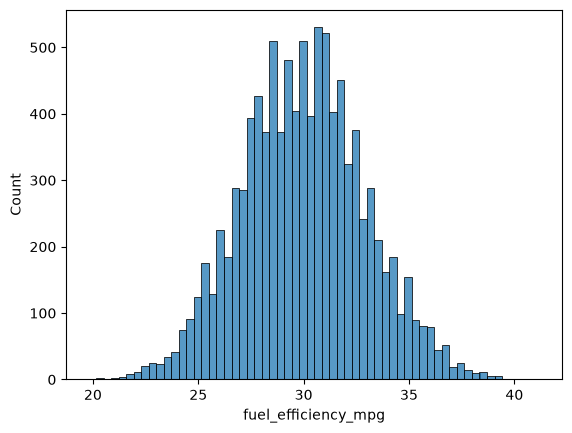

In [18]:
sns.histplot(df.fuel_efficiency_mpg)

In [19]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [20]:
df.describe()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.000000,10000.00000,10000.000000,10000.000000,9123.000000,10000.000000,9736.000000,10000.000000
mean,1999.549500,3.50400,2268.807000,6.035200,254.446016,4286.754000,18.888044,29.997700
std,14.207925,0.95209,183.447355,0.542578,22.844613,266.212491,1.279543,2.930245
min,1975.000000,2.00000,1590.000000,4.000000,171.000000,3320.000000,14.000000,19.800000
25%,1987.000000,3.00000,2150.000000,6.000000,239.000000,4110.000000,18.000000,28.000000
50%,2000.000000,4.00000,2270.000000,6.000000,254.000000,4280.000000,18.900000,30.000000
75%,2012.000000,4.00000,2390.000000,6.000000,270.000000,4470.000000,19.700000,31.900000
max,2024.000000,5.00000,3110.000000,8.000000,334.000000,5460.000000,23.800000,41.200000


In [21]:
df.index


RangeIndex(start=0, stop=10000, step=1)

In [22]:
a=df.isnull().sum()

In [23]:
print(a)

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64


In [24]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [25]:
n=len(df)

In [26]:
n_val=int(0.2*n)
n_test=int(0.2*n)
n_train=int(n-n_val-n_test)

In [27]:
n_train

6000

In [28]:
n

10000

In [29]:
n_val,
n_test

2000

In [30]:
n_test

2000

In [31]:
n,n_val,n_test,n_train

(10000, 2000, 2000, 6000)

In [32]:
df.iloc[:10]

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
5,2007,USA,Hybrid,Front-wheel drive,2,2290,6,266.0,4260,18.8,31.2
6,1992,Asia,Gasoline,Front-wheel drive,2,2270,6,250.0,4310,21.7,26.8
7,2005,USA,Gasoline,Front-wheel drive,4,2370,6,279.0,4090,17.4,30.2
8,1997,Asia,Gasoline,Rear-wheel drive,3,2330,6,251.0,4230,19.5,30.9
9,2004,USA,Diesel,All-wheel drive,5,2330,6,280.0,4620,17.7,31.2


In [33]:
df_val=df.iloc[:n_val]
df_test=df.iloc[n_val:n_val+n_test]
df_train=df.iloc[n_val+n_test:]

In [34]:
df_val

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
1995,1976,Europe,Gasoline,Rear-wheel drive,4,2390,6,NaN,4090,16.9,29.6
1996,1999,USA,Gasoline,All-wheel drive,4,2110,6,252.0,4270,19.4,28.0
1997,1983,Asia,Diesel,Rear-wheel drive,3,1960,6,226.0,4240,17.8,27.7
1998,2021,USA,Hybrid,Rear-wheel drive,4,2330,6,278.0,4480,17.5,32.9


In [35]:
df_test

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
2000,2001,Europe,Gasoline,Front-wheel drive,4,1860,6,225.0,3860,18.1,33.4
2001,2023,USA,Gasoline,Front-wheel drive,4,1840,5,198.0,3790,17.4,34.8
2002,1987,USA,Diesel,Rear-wheel drive,3,2320,6,276.0,4500,19.7,28.3
2003,1983,USA,Gasoline,Front-wheel drive,3,2240,6,276.0,4300,17.8,26.4
2004,2015,USA,Gasoline,Front-wheel drive,4,2450,7,268.0,4670,17.4,29.5
...,...,...,...,...,...,...,...,...,...,...,...
3995,2005,Asia,Gasoline,Front-wheel drive,4,2430,6,267.0,4310,18.5,28.3
3996,2023,Asia,Diesel,Rear-wheel drive,5,2040,6,243.0,4550,19.2,34.9
3997,2007,Asia,Gasoline,Front-wheel drive,3,2550,6,269.0,4010,18.9,29.6
3998,1989,Asia,Gasoline,Front-wheel drive,2,2420,6,260.0,4270,18.3,27.3


In [36]:
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
4000,1980,USA,Gasoline,Front-wheel drive,5,2450,6,262.0,4530,19.2,24.8
4001,2017,Europe,Gasoline,Front-wheel drive,4,2310,6,258.0,4420,18.9,32.7
4002,2022,Europe,Gasoline,Front-wheel drive,2,2010,5,217.0,3880,19.8,36.7
4003,1980,Europe,Gasoline,Front-wheel drive,4,2330,6,NaN,4410,20.0,29.8
4004,2023,Europe,Gasoline,Rear-wheel drive,4,2490,7,262.0,4420,18.9,29.1
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [37]:
import random 
random.seed(40459876)
print(random.randint(1,100))

25


In [38]:
np.random.seed(22)

idx=np.arange(n)
np.random.shuffle(idx)

In [39]:
len(df_train),len(df_val),len(df_test)

(6000, 2000, 2000)

In [40]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [41]:
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,1980,USA,Gasoline,Front-wheel drive,5,2450,6,262.0,4530,19.2,24.8
1,2017,Europe,Gasoline,Front-wheel drive,4,2310,6,258.0,4420,18.9,32.7
2,2022,Europe,Gasoline,Front-wheel drive,2,2010,5,217.0,3880,19.8,36.7
3,1980,Europe,Gasoline,Front-wheel drive,4,2330,6,NaN,4410,20.0,29.8
4,2023,Europe,Gasoline,Rear-wheel drive,4,2490,7,262.0,4420,18.9,29.1
...,...,...,...,...,...,...,...,...,...,...,...
5995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
5996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
5997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
5998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [42]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [43]:
base=[
    'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',

]
    

In [44]:
X_train=df_train[base].values
y_train=df_train['fuel_efficiency_mpg'].values

X_val=df_val[base].values
y_train=df_val['fuel_efficiency_mpg'].values

In [45]:
df_train[base].isnull().sum()

engine_displacement      0
horsepower             501
vehicle_weight           0
model_year               0
dtype: int64

In [46]:
X_train=df_train[base].fillna(0).values
X_val_zero=df_val[base].fillna(0).values

In [47]:
mean_value = df_train['engine_displacement'].mean()

In [48]:
X_train_mean = df_train[base].fillna(mean_value).values
X_val_mean = df_val[base].fillna(mean_value).values

In [49]:
df[base].isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

In [50]:
df[base].isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

In [51]:
def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])

    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)

    w_full=XTX_inv.dot(X.T).dot(y)

    return w_full[0],w_full[1:]

In [52]:
def prepare_X(df):
    df_n=df[base]
    df_n=df_n.fillna(0).values
    X=df_n
    return X

In [53]:
# Step 1: Define target variables first
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values

# Step 2: Prepare training features
X_train = prepare_X(df_train)

# Step 3: Train the model
w0, w = train_linear_regression(X_train, y_train)

# Step 4: Prepare validation features
X_val = prepare_X(df_val)

# Step 5: Predict
y_pred = w0 + X_val.dot(w)

# Step 6: Calculate RMSE
score = rmse(y_val, y_pred)

print(score)

NameError: name 'rmse' is not defined

In [56]:
X_train=prepare_x(df_train)
w0,w=train_linear_regression(X_train,y_train) 
y_train=df_train['fuel_efficiency_mpg'].values
y_val=df_val['fuel_efficiency_mpg'].values

NameError: name 'prepare_x' is not defined

In [57]:
base

['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [58]:
mean_value1=df_train['fuel_efficiency_mpg'].mean()

In [59]:
def prepare_X1(df):
    df_n=df[base]
    df_n=df_n.fillna(mean_value1).values
    X=df_n
    return X

In [60]:
# Step 1: Define target variables first
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values

# Step 2: Prepare training features
X_train = prepare_X1(df_train)

# Step 3: Train the model
w0, w = train_linear_regression(X_train, y_train)

# Step 4: Prepare validation features
X_val = prepare_X1(df_val)

# Step 5: Predict
y_pred = w0 + X_val.dot(w)

# Step 6: Calculate RMSE
score = rmse(y_val, y_pred)



NameError: name 'rmse' is not defined

In [61]:
type(score)

NameError: name 'score' is not defined

In [62]:
def rmse(y,y_predict):
    rmse=np.sqrt(np.mean((y-y_predict))**2)
    print(rmse)

In [68]:
#r=[0, 0.01, 0.1, 1, 5, 10, 100]

In [74]:
def train_linear_regression_reg(X, y, r=1):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [78]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r101)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

NameError: name 'r101' is not defined